## 1. Imports and settings

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

SEED = 42
CATS = ["Product Quality", "Pricing/Billing", "Delivery Delay",
        "Staff Behaviour", "Hygiene/Cleanliness", "Other"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 2. Load and explore the dataset

In [2]:
df = pd.read_csv("pune_shop_complaints.csv")
print("Shape:", df.shape)
df.head(8)

Shape: (1500, 4)


,complaint,category,shop_type,area
0,"The bill amount is wrong, extra money was adde...",Pricing/Billing,Medical,Hadapsar
1,"At the medical shop in Baner, i did not like t...",Staff Behaviour,Medical,Baner
2,The earphones is defective and I want a replac...,Product Quality,Electronics,Kondhwa
3,"Big problem here, someone should visit and see...",Product Quality,Electronics,Katraj
4,I was not given any bill for the cough syrup I...,Pricing/Billing,Medical,Hadapsar
5,Price of cooking oil is different from the boa...,Pricing/Billing,Kirana,Kothrud
6,Staff ignored me and attended to other custome...,Staff Behaviour,Electronics,Baner
7,The counter staff was impolite and used bad words,Staff Behaviour,Kirana,Kondhwa


In [3]:
print(df["shop_type"].value_counts(), "\n")
print(df["area"].value_counts())

shop_type
Medical        519
Electronics    495
Kirana         486
Name: count, dtype: int64 

area
Hadapsar    213
Kothrud     206
Warje       194
Baner       190
Wakad       186
Katraj      176
Kondhwa     174
Narhe       161
Name: count, dtype: int64


### Class distribution – is the data balanced?
A problem is **imbalanced** when some classes have many more examples than others. Here *Product Quality* is about 3.8 times larger than *Other*.

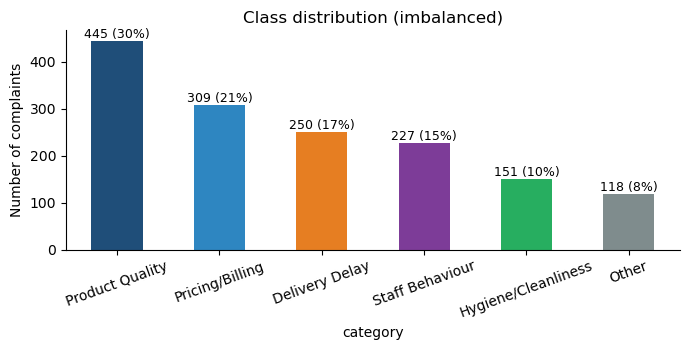

Majority-class baseline accuracy: 0.297


In [4]:
counts = df["category"].value_counts().reindex(CATS)
ax = counts.plot(kind="bar", figsize=(7, 3.6), color=["#1f4e79", "#2e86c1", "#e67e22", "#7d3c98", "#27ae60", "#7f8c8d"], rot=20)
for i, v in enumerate(counts): ax.text(i, v + 6, f"{v} ({v/len(df):.0%})", ha="center", fontsize=9)
ax.set_ylabel("Number of complaints"); ax.set_title("Class distribution (imbalanced)")
plt.tight_layout(); plt.show()
print("Majority-class baseline accuracy:", round(counts.max() / len(df), 3))

## 3. Train–test split and TF-IDF features
* **Stratified** 80:20 split keeps the same class proportions in both parts.
* **TF-IDF** turns text into numbers. It is fitted on the **training text only** to avoid data leakage.

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(df["complaint"], df["category"], test_size=0.2,
                                          stratify=df["category"], random_state=SEED)
tfidf = TfidfVectorizer(lowercase=True, stop_words="english", ngram_range=(1, 2), min_df=2, sublinear_tf=True)
A_tr = tfidf.fit_transform(X_tr)
A_te = tfidf.transform(X_te)
print("Train:", A_tr.shape, " Test:", A_te.shape)
print("Example features:", list(tfidf.get_feature_names_out()[:12]))

Train: (1200, 1248)  Test: (300, 1248)
Example features: ['accept', 'accept card', 'accept return', 'acceptable', 'acceptable acceptable', 'acceptable complained', 'acceptable kindly', 'acceptable look', 'acceptable visited', 'action', 'action family', 'action happened']


## 4. Train and tune the five classifiers
Each model is tuned with **5-fold cross-validation + grid search** on the training set (scoring = macro F1), then tested once on the unseen test set.

In [6]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
results, models, preds = {}, {}, {}

def run(name, est, grid):
    gs = GridSearchCV(est, grid, cv=cv, scoring="f1_macro", n_jobs=-1).fit(A_tr, y_tr)
    model = gs.best_estimator_
    pred = model.predict(A_te)
    cvs = cross_val_score(model, A_tr, y_tr, cv=cv, scoring="accuracy")
    p, r, f, _ = precision_recall_fscore_support(y_te, pred, average="macro", zero_division=0)
    results[name] = {"Best params": gs.best_params_, "Accuracy": accuracy_score(y_te, pred),
                     "Macro P": p, "Macro R": r, "Macro F1": f,
                     "Weighted F1": precision_recall_fscore_support(y_te, pred, average="weighted", zero_division=0)[2],
                     "CV acc (mean)": cvs.mean(), "CV acc (std)": cvs.std()}
    models[name], preds[name] = model, pred

run("KNN", KNeighborsClassifier(metric="cosine"), {"n_neighbors": [1, 3, 5, 7, 9, 11, 15]})
run("Linear SVM", LinearSVC(random_state=SEED, max_iter=10000), {"C": [0.1, 0.5, 1, 2, 5]})
run("RBF SVM", SVC(kernel="rbf"), {"C": [0.5, 1, 5, 10, 50], "gamma": ["scale", 0.5, 1, 2]})
run("Logistic Regression", LogisticRegression(max_iter=2000, random_state=SEED), {"C": [0.5, 1, 5, 10, 50]})
run("Naive Bayes", MultinomialNB(), {"alpha": [0.01, 0.05, 0.1, 0.5, 1.0]})

res_df = pd.DataFrame(results).T
res_df.style.format({c: "{:.3f}" for c in res_df.columns if c != "Best params"})

,Best params,Accuracy,Macro P,Macro R,Macro F1,Weighted F1,CV acc (mean),CV acc (std)
KNN,{'n_neighbors': 11},0.773,0.756,0.781,0.766,0.774,0.741,0.030
Linear SVM,{'C': 0.5},0.813,0.812,0.787,0.797,0.812,0.809,0.024
RBF SVM,"{'C': 1, 'gamma': 1}",0.813,0.811,0.796,0.803,0.813,0.787,0.022
Logistic Regression,{'C': 5},0.820,0.825,0.793,0.807,0.819,0.803,0.036
Naive Bayes,{'alpha': 0.5},0.793,0.793,0.774,0.782,0.792,0.781,0.020


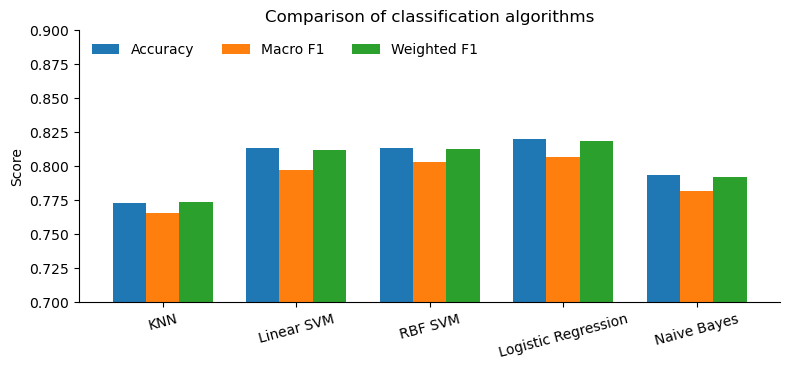

Best model by macro F1: Logistic Regression

Note: the test set has only 300 rows (1 complaint = 0.33%). Differences among the top three models are within cross-validation noise.


In [7]:
ax = res_df[["Accuracy", "Macro F1", "Weighted F1"]].astype(float).plot(kind="bar", figsize=(8, 3.8), rot=15, width=0.75)
ax.set_ylim(0.7, 0.9); ax.set_ylabel("Score"); ax.set_title("Comparison of classification algorithms")
ax.legend(frameon=False, ncol=3, loc="upper left")
plt.tight_layout(); plt.show()
best = res_df["Macro F1"].astype(float).idxmax()
print("Best model by macro F1:", best)
print("\nNote: the test set has only 300 rows (1 complaint = 0.33%). Differences among the top three models are within cross-validation noise.")

## 5. Multiclass confusion matrix
Rows = **actual** class, columns = **predicted** class. The diagonal = correct predictions.

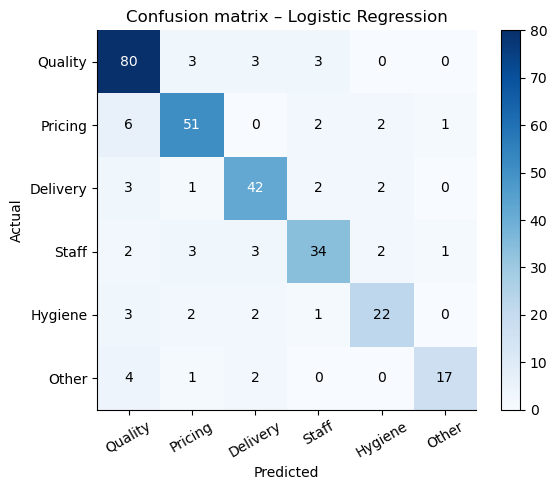

Correct: 246 of 300


In [8]:
short = ["Quality", "Pricing", "Delivery", "Staff", "Hygiene", "Other"]
cm = confusion_matrix(y_te, preds[best], labels=CATS)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(6)); ax.set_yticks(range(6)); ax.set_xticklabels(short, rotation=30); ax.set_yticklabels(short)
for i in range(6):
    for j in range(6):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max()/2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual"); ax.set_title(f"Confusion matrix – {best}")
plt.colorbar(im, fraction=0.046); plt.tight_layout(); plt.show()
print("Correct:", cm.trace(), "of", cm.sum())

## 6. Per-class precision, recall and F1

In [9]:
print(classification_report(y_te, preds[best], labels=CATS, zero_division=0))

                     precision    recall  f1-score   support

    Product Quality       0.82      0.90      0.86        89
    Pricing/Billing       0.84      0.82      0.83        62
     Delivery Delay       0.81      0.84      0.82        50
    Staff Behaviour       0.81      0.76      0.78        45
Hygiene/Cleanliness       0.79      0.73      0.76        30
              Other       0.89      0.71      0.79        24

           accuracy                           0.82       300
          macro avg       0.83      0.79      0.81       300
       weighted avg       0.82      0.82      0.82       300



*Precision* = TP / (TP + FP), *Recall* = TP / (TP + FN), *F1* = harmonic mean of both.
Notice the small class **Other**: high precision but low recall (the model is right when it says "Other", but misses many real "Other" complaints).

## 7. Macro, Micro and Weighted averaging
* **Macro** – plain average of per-class scores (every class equal).
* **Micro** – pool TP/FP/FN of all classes first (for single-label multiclass = accuracy).
* **Weighted** – average weighted by class size.

In [10]:
rows = []
for avg in ["macro", "micro", "weighted"]:
    p, r, f, _ = precision_recall_fscore_support(y_te, preds[best], average=avg, zero_division=0)
    rows.append([avg.capitalize(), p, r, f])
avg_df = pd.DataFrame(rows, columns=["Averaging", "Precision", "Recall", "F1"]).set_index("Averaging")
display(avg_df.round(3))
print("Accuracy =", round(accuracy_score(y_te, preds[best]), 3), " (equals the micro average)")

,Precision,Recall,F1
Averaging,,,
Macro,0.825,0.793,0.807
Micro,0.820,0.820,0.820
Weighted,0.821,0.820,0.819


Accuracy = 0.82  (equals the micro average)


## 8. Kernel functions in SVM
Same C and gamma for all kernels (RBF, polynomial, sigmoid, linear) to compare them fairly.

In [11]:
rows = []
for k in ["linear", "poly", "rbf", "sigmoid"]:
    m = SVC(kernel=k, C=10, gamma="scale", degree=3, random_state=SEED).fit(A_tr, y_tr)
    pr = m.predict(A_te)
    rows.append([k, accuracy_score(y_te, pr), precision_recall_fscore_support(y_te, pr, average="macro", zero_division=0)[2]])
display(pd.DataFrame(rows, columns=["Kernel", "Accuracy", "Macro F1"]).set_index("Kernel").round(3))

,Accuracy,Macro F1
Kernel,,
linear,0.777,0.761
poly,0.780,0.768
rbf,0.803,0.788
sigmoid,0.767,0.740


### Decision boundary: linear vs RBF kernel (toy 2-D data)
Text data has thousands of dimensions and cannot be drawn, so this picture uses a small 2-D toy dataset to show the idea.

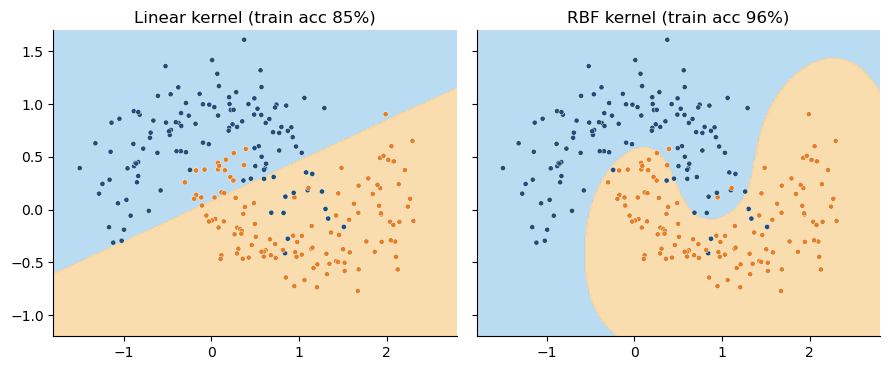

In [12]:
from sklearn.datasets import make_moons
from matplotlib.colors import ListedColormap
Zt, yt = make_moons(n_samples=240, noise=0.22, random_state=SEED)
gx, gy = np.meshgrid(np.linspace(-1.8, 2.8, 300), np.linspace(-1.2, 1.7, 300))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for ax, (nm, mdl) in zip(axes, [("Linear kernel", SVC(kernel="linear", C=1)), ("RBF kernel", SVC(kernel="rbf", C=5, gamma=1.5))]):
    mdl.fit(Zt, yt)
    zz = mdl.predict(np.c_[gx.ravel(), gy.ravel()]).reshape(gx.shape)
    ax.contourf(gx, gy, zz, cmap=ListedColormap(["#aed6f1", "#fad7a0"]), alpha=0.85)
    ax.scatter(Zt[:, 0], Zt[:, 1], c=yt, cmap=ListedColormap(["#1f4e79", "#e67e22"]), s=14, edgecolor="white", linewidth=0.3)
    ax.set_title(f"{nm} (train acc {mdl.score(Zt, yt):.0%})")
plt.tight_layout(); plt.show()

## 9. Handling class imbalance
`class_weight="balanced"` punishes mistakes on small classes more strongly during training.

In [13]:
c_best = results["Linear SVM"]["Best params"]["C"]
rows = []
for tag, cw in [("Without class weights", None), ("class_weight='balanced'", "balanced")]:
    m = LinearSVC(C=c_best, class_weight=cw, random_state=SEED, max_iter=10000).fit(A_tr, y_tr)
    pr = m.predict(A_te)
    p, r, f, _ = precision_recall_fscore_support(y_te, pr, labels=CATS, zero_division=0)
    rows.append([tag, accuracy_score(y_te, pr), f.mean(), r[4], r[5]])
display(pd.DataFrame(rows, columns=["Setting", "Accuracy", "Macro F1", "Recall: Hygiene", "Recall: Other"]).set_index("Setting").round(3))

,Accuracy,Macro F1,Recall: Hygiene,Recall: Other
Setting,,,,
Without class weights,0.813,0.797,0.700,0.708
class_weight='balanced',0.820,0.801,0.767,0.708


## 10. One-vs-Rest vs One-vs-One (multiclass strategy for SVM)
* **One-vs-Rest:** 1 classifier per class → 6 classifiers.
* **One-vs-One:** 1 classifier per pair of classes → 6×5/2 = 15 classifiers.

In [14]:
rows = []
for tag, w in [("One-vs-Rest", OneVsRestClassifier(LinearSVC(C=c_best, random_state=SEED, max_iter=10000))),
               ("One-vs-One", OneVsOneClassifier(LinearSVC(C=c_best, random_state=SEED, max_iter=10000)))]:
    w.fit(A_tr, y_tr); pr = w.predict(A_te)
    rows.append([tag, len(w.estimators_), accuracy_score(y_te, pr),
                 precision_recall_fscore_support(y_te, pr, average="macro", zero_division=0)[2]])
display(pd.DataFrame(rows, columns=["Strategy", "No. of classifiers", "Accuracy", "Macro F1"]).set_index("Strategy").round(3))

,No. of classifiers,Accuracy,Macro F1
Strategy,,,
One-vs-Rest,6,0.813,0.797
One-vs-One,15,0.797,0.784


## 11. Live demo – classify a new complaint
Change the text in `my_complaints` and run the cell. (Confidence is the model's probability for the predicted class.)

In [15]:
final = models["Logistic Regression"]

def classify(texts):
    A = tfidf.transform(texts)
    proba = final.predict_proba(A)
    out = pd.DataFrame({"Complaint": texts,
                        "Predicted category": final.classes_[proba.argmax(1)],
                        "Confidence": proba.max(1).round(2)})
    return out

my_complaints = [
    "The milk packet I bought this morning was sour and expired",
    "Shopkeeper charged me 20 rupees extra over the printed MRP",
    "My mixer grinder order is still not delivered after three days",
    "The salesman shouted at me and refused to listen",
    "There are flies everywhere and the floor is very dirty",
    "No place to park my scooter near this shop",
]
pd.set_option("display.max_colwidth", 80)
classify(my_complaints)

,Complaint,Predicted category,Confidence
0,The milk packet I bought this morning was sour and expired,Product Quality,0.83
1,Shopkeeper charged me 20 rupees extra over the printed MRP,Pricing/Billing,0.97
2,My mixer grinder order is still not delivered after three days,Delivery Delay,0.54
3,The salesman shouted at me and refused to listen,Staff Behaviour,0.95
4,There are flies everywhere and the floor is very dirty,Hygiene/Cleanliness,0.47
5,No place to park my scooter near this shop,Other,0.64


### Most important words per category (Logistic Regression)

In [16]:
vocab = np.array(tfidf.get_feature_names_out())
for i, c in enumerate(final.classes_):
    print(f"{c:22s}:", ", ".join(vocab[np.argsort(final.coef_[i])[::-1][:6]]))

Delivery Delay        : delivery, delayed, reached, order, parcel, late
Hygiene/Cleanliness   : kothrud did, washing hands, shopkeeper handles, washing, gloves, hands
Other                 : variety, dirty, light fan, fan, fan working, light
Pricing/Billing       : given, staff helpful, helpful, twice, discount, discount promised
Product Quality       : insects, packet, defective, defective want, replacement, want replacement
Staff Behaviour       : crowded, shop crowded, rudely, customers, salesman, salesman arrogant


## 12. Summary
* Best models reach about **80–82 % accuracy / ~0.80 macro F1** on 6 classes (random guess ≈ 17 %, majority class ≈ 30 %).
* Logistic Regression, Linear SVM and RBF SVM perform about equally; KNN is the weakest.
* Small classes (*Hygiene*, *Other*) are the hardest – use **macro F1** and per-class recall, not accuracy alone.
* Remaining errors come from mixed / vague complaints and label noise built into the data.